<a href="https://colab.research.google.com/github/MelodyZuo/Databootcamp-Regression-Competition-for-house-prices/blob/main/intro_decision_tree_updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Decision Trees: Rules, Entropy, Depth, Lift, and Gain

## A student-centered classification lesson

Today we will build a decision tree by moving through the same decisions the algorithm makes:

1. propose a rule for splitting customers;
2. measure whether a split creates purer groups;
3. fit and visualize a `DecisionTreeClassifier`;
4. explore what changes as a tree grows deeper;
5. compare a decision tree with logistic regression using lift and cumulative gain.

### Learning goals

By the end of class, you should be able to:

- express a classification rule using feature thresholds;
- explain entropy as a measure of uncertainty or class impurity;
- compare candidate splits using weighted entropy and information gain;
- fit and control a scikit-learn decision tree;
- recognize underfitting and overfitting from train/test results;
- use lift and cumulative gain to compare ranked model predictions.

### Group roles

Work in groups of two or three and rotate roles after each investigation:

- **Driver:** types and runs code.
- **Navigator:** reads the prompt and documentation and proposes the next step.
- **Skeptic:** challenges the rule, calculation, or interpretation.

## Lesson map

| Time | Student activity |
|---:|---|
| 0–15 min | Explore churn and invent a classification rule |
| 15–35 min | Learn entropy and compare two splits by hand |
| 35–50 min | Test candidate splits on the churn data |
| 50–65 min | Fit and visualize a decision tree |
| 65–78 min | Explore tree depth and overfitting |
| 78–100 min | Compare the tree and logistic regression with gain and lift |
| 100–105 min | Report and exit reflection |

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid")

## 1. The business question

A telecommunications company wants to identify customers likely to stop using its service. We will call this event **churn**.

We begin with two features:

- `day_mins`: daytime minutes used;
- `custserv_calls`: number of customer-service calls.

Before using an algorithm, your group will act as the decision tree.

In [6]:
url = "https://raw.githubusercontent.com/jfkoehler/nyu_bootcamp_fa24/refs/heads/main/data/cell_phone_churn.csv"
churn = pd.read_csv(url)

churn.head()

,state,account_length,area_code,intl_plan,vmail_plan,vmail_message,day_mins,day_calls,day_charge,eve_mins,eve_calls,eve_charge,night_mins,night_calls,night_charge,intl_mins,intl_calls,intl_charge,custserv_calls,churn
0,KS,128,415,no,yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,no,yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,no,no,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,yes,no,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,yes,no,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


### Quick data check — divide the work

Answer these questions before modeling:

1. How many customers and columns are present?
2. Are any values missing?
3. What proportion of customers churned?
4. What accuracy would we get by always predicting the most common class?
5. What other feature in the dataset might help predict churn?

Each group member should answer at least one question, then share the result.

In [ ]:
# Use .shape, .isna(), .value_counts(), or other pandas methods here.

## 2. Invent a rule before fitting a model

Study the graph below. Your group must propose a rule using `day_mins`, `custserv_calls`, or both.

Examples of the **form** of a rule—not recommended values—include:

> Predict churn when `custserv_calls` is greater than ___

or

> Predict churn when `day_mins` is greater than ___ **or** `custserv_calls` is greater than ___

The objective is not to guess perfectly. It is to make your assumptions explicit and testable.

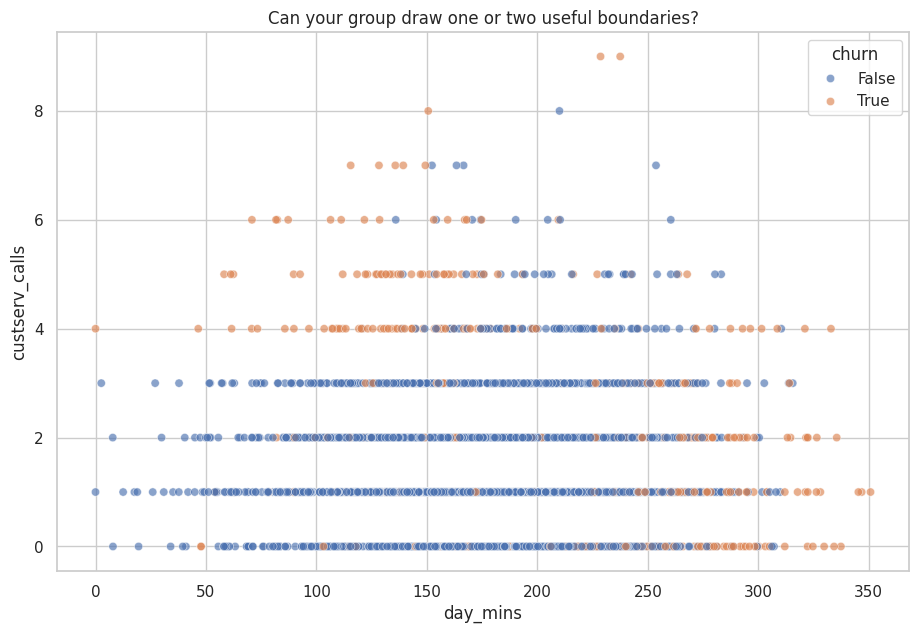

In [7]:
plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=churn,
    x="day_mins",
    y="custserv_calls",
    hue="churn",
    alpha=0.65,
)
plt.title("Can your group draw one or two useful boundaries?");

### Group rule

Write the rule in words first.

> **Our rule:**  
> **Why we chose it:**  
> **Where we expect it to fail:**

Then translate it into pandas conditions below. Store the resulting zero/one predictions in `human_prediction`.

In [8]:
# Example structure—replace the thresholds and logic with your group's rule.
human_prediction = (
     (churn["day_mins"] > 240)
     | (churn["custserv_calls"] > 4)
 ).astype(int)

### Evaluate the human rule

Convert the target to zeroes and ones if necessary, then compare your rule with the majority-class baseline.

Baseline accuracy: 0.8550855085508551
Human-rule accuracy: 0.8397839783978398


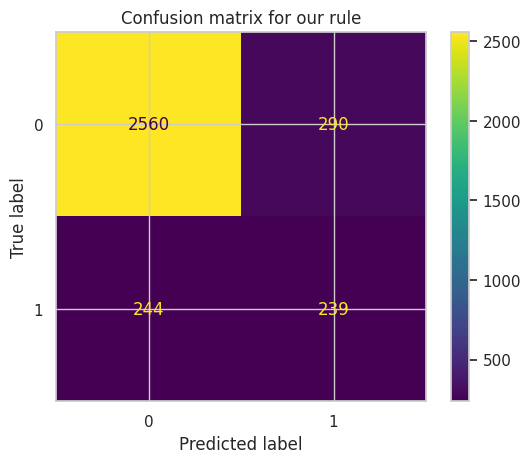

In [11]:
# This handles Boolean, numeric, and common Yes/No encodings.
if churn["churn"].dtype == "object":
    y_all = (
        churn["churn"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map({"yes": 1, "true": 1, "1": 1, "no": 0, "false": 0, "0": 0})
    )
else:
    y_all = churn["churn"].astype(int)

print("Baseline accuracy:", y_all.value_counts(normalize=True).max())

# Uncomment after creating human_prediction.
print("Human-rule accuracy:", accuracy_score(y_all, human_prediction))
ConfusionMatrixDisplay.from_predictions(y_all, human_prediction)
plt.title("Confusion matrix for our rule");

### Discuss

- Did your rule beat the baseline?
- Which kind of mistake occurred more often?
- Would changing one threshold help?
- Why is trial-and-error an inefficient way to search through many possible splits?

## 3. Entropy: measuring uncertainty in a group

A decision tree needs a numerical way to compare splits. One common measure is **entropy**:

$$
H(S)=-\sum_{i=1}^{k} p_i\log_2(p_i)
$$

For a binary target:

- entropy is **0** when a group is completely pure—all churn or all non-churn;
- entropy is **1** when the group is evenly divided—maximum uncertainty;
- values between 0 and 1 represent different degrees of class mixture.

The tree prefers a split whose child groups have low **weighted entropy**.

$$
H_{\text{split}}=\frac{n_L}{n}H(L)+\frac{n_R}{n}H(R)
$$

The reduction in entropy is called **information gain**:

$$
\text{Information Gain}=H(\text{parent})-H_{\text{split}}
$$

In [30]:
def binary_entropy(positive, total):
    # Entropy of a binary group containing `positive` positive cases.
    if total == 0:
        return 0.0
    p = positive / total
    if p == 0 or p == 1:
        return 0.0
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))


for positive in [0, 1, 2, 3, 4, 5, 6]:
    print(positive, "positive out of 6 ->", round(binary_entropy(positive, 6), 3))

0 positive out of 6 -> 0.0
1 positive out of 6 -> 0.65
2 positive out of 6 -> 0.918
3 positive out of 6 -> 1.0
4 positive out of 6 -> 0.918
5 positive out of 6 -> 0.65
6 positive out of 6 -> 0.0


### Entropy problem — which split is better?

A parent node contains **12 customers: 6 churned and 6 stayed**.

Two candidate rules create these child groups:

| Candidate | Left group | Right group |
|---|---|---|
| **Split A** | 5 churn, 1 stay | 1 churn, 5 stay |
| **Split B** | 4 churn, 2 stay | 2 churn, 4 stay |

Without running the next code cell:

1. Find the entropy of the parent.
2. Find the entropy of each child in Split A.
3. Find the weighted entropy and information gain of Split A.
4. Repeat for Split B.
5. Which split should a decision tree choose? Explain the result in ordinary language.

Each person should calculate one child entropy. Compare results before continuing.

In [39]:
# Use binary_entropy() to check your group's calculations.
binary_entropy(1,6)

parent_entropy = binary_entropy(6, 12)

# Complete these calculations.
split_a_entropy = binary_entropy(1,6)
split_a_gain = parent_entropy - binary_entropy(1,6)
split_b_entropy = binary_entropy(2,6)
split_b_gain = parent_entropy - binary_entropy(2,6)

print('split_a_entropy:', split_a_entropy)
print('split_a_gain:', split_a_gain)
print('split_b_entropy:', split_b_entropy)
print('split_b_gain:', split_b_gain)

split_a_entropy: 0.6500224216483541
split_a_gain: 0.3499775783516459
split_b_entropy: 0.9182958340544896
split_b_gain: 0.08170416594551044


### Interpretation checkpoint

Complete both sentences:

> Split A is better because the entropy is smaller, and it has a greater gain (more difference).

> Lower entropy does **not** mean the groups are smaller; it means the group has a more pure split.

## 4. Test candidate splits on the churn data

The function below calculates the weighted entropy and information gain produced by a numerical threshold. Read it with your group and connect each section to the formulas above.

In [69]:
def evaluate_split(data, feature = 'custserv_calls', threshold = 3, target="churn_binary"):
    parent = data[target]
    left = data.loc[data[feature] <= threshold, target]
    right = data.loc[data[feature] > threshold, target]

    parent_h = binary_entropy(parent.sum(), len(parent))
    left_h = binary_entropy(left.sum(), len(left))
    right_h = binary_entropy(right.sum(), len(right))

    weighted_h = (len(left) / len(parent)) * left_h + (len(right) / len(parent)) * right_h

    return pd.Series({
        "feature": feature,
        "threshold": threshold,
        "left_size": len(left),
        "right_size": len(right),
        "weighted_entropy": weighted_h,
        "information_gain": parent_h - weighted_h,
    })


churn["churn_binary"] = y_all

### Split tournament

Each group should test at least:

- three possible thresholds for `day_mins`;
- three possible thresholds for `custserv_calls`.

Include the thresholds from your original human rule. Collect the results in a DataFrame and identify the strongest single split.

In [59]:
candidate_results = []

# Example—replace or expand these values.
for threshold in [150, 200, 250]:
    candidate_results.append(evaluate_split(churn, "day_mins", threshold))

for threshold in [1, 3, 5]:
    candidate_results.append(evaluate_split(churn, "custserv_calls", threshold))

split_results = pd.DataFrame(candidate_results).sort_values(
    "information_gain", ascending=False
)
split_results

,feature,threshold,left_size,right_size,weighted_entropy,information_gain
4,custserv_calls,3,3066,267,0.546873,0.050093
2,day_mins,250,3005,328,0.547461,0.049506
1,day_mins,200,2147,1186,0.579143,0.017823
5,custserv_calls,5,3298,35,0.587532,0.009434
3,custserv_calls,1,1878,1455,0.589825,0.007141
0,day_mins,150,979,2354,0.595219,0.001747


> **Best split tested:**  
> **Evidence:**  
> **How it compares with our human rule:**

## 5. Implement `DecisionTreeClassifier`

The tree can search across many candidate splits and repeat the process in each child node.

Use only `day_mins` and `custserv_calls` at first so that we can visualize the result.

Documentation:

- [`DecisionTreeClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)
- [`plot_tree`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.plot_tree.html)

In [73]:
features = ["day_mins", "custserv_calls"]
X = churn[features]
y = churn["churn_binary"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y,
)

### Build the first tree

1. Instantiate a `DecisionTreeClassifier` with `criterion="entropy"`, `max_depth=2`, and `random_state=42`.
2. Fit it using the training data.
3. Calculate training accuracy, test accuracy, and baseline test accuracy.
4. Display the test confusion matrix.

In [84]:
tree = DecisionTreeClassifier(criterion="entropy",max_depth=2,random_state=42)
tree.fit(X, y)

print("Training accuracy:", tree.score(X_train, y_train))
print('Test accuracy:', tree.score(X_test, y_test))
print("Test baseline:", y_train.value_counts(normalize=True))

Training accuracy: 0.8727490996398559
Test accuracy: 0.8573141486810552
Test baseline: churn_binary
0    0.855142
1    0.144858
Name: proportion, dtype: float64


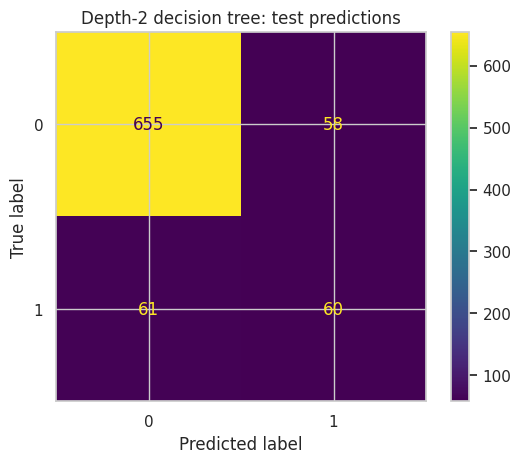

In [85]:
ConfusionMatrixDisplay.from_estimator(tree, X_test, y_test)
plt.title("Depth-2 decision tree: test predictions");

### Read the tree as a set of rules

Run the visualization after fitting `tree`. Then translate one path from the root to a leaf into an `if/then` statement.

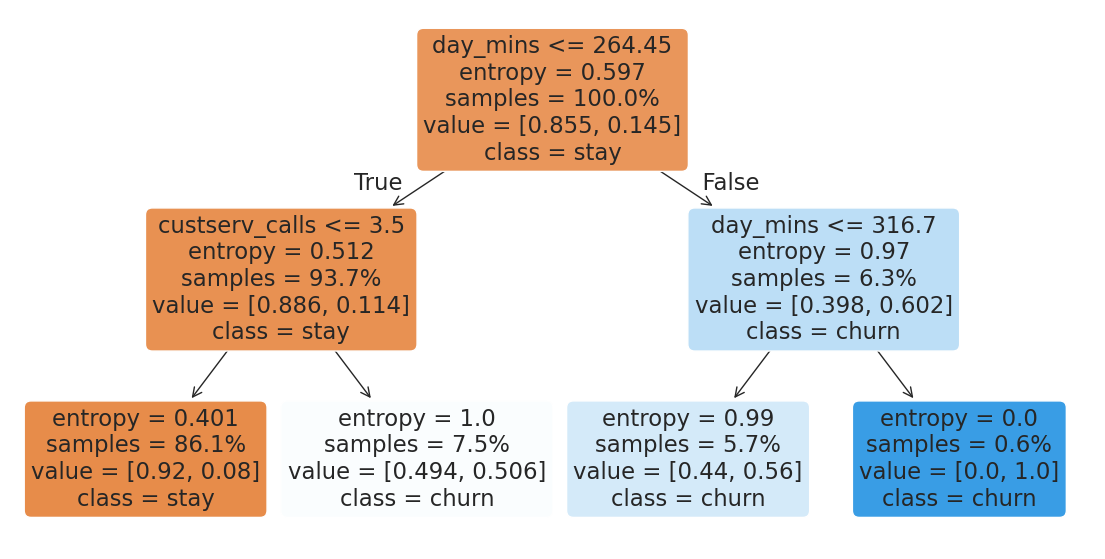

In [89]:
plt.figure(figsize=(14, 7))
plot_tree(
     tree,
     feature_names=features,
     class_names=["stay", "churn"],
     filled=True,
     rounded=True,
     proportion=True,
 )
plt.show()

> **One path through the tree:**  
> **What the entropy shown in the final leaf tells us:**

## 6. What changes when the tree grows deeper?

Before running the experiment, predict:

- What will happen to training accuracy as `max_depth` increases?
- Must test accuracy always increase?
- What will happen to the number of leaves?

In [90]:
depth_results = []

for depth in range(1, 16):
    depth_tree = DecisionTreeClassifier(
        criterion="entropy",
        max_depth=depth,
        random_state=42,
    )
    depth_tree.fit(X_train, y_train)

    depth_results.append({
        "max_depth": depth,
        "train_accuracy": depth_tree.score(X_train, y_train),
        "test_accuracy": depth_tree.score(X_test, y_test),
        "leaves": depth_tree.get_n_leaves(),
    })

depth_results = pd.DataFrame(depth_results)
depth_results

,max_depth,train_accuracy,test_accuracy,leaves
0,1,0.869548,0.859712,2
1,2,0.871949,0.856115,4
2,3,0.892757,0.881295,7
3,4,0.897559,0.876499,13
4,5,0.902761,0.878897,24
5,6,0.905162,0.876499,37
6,7,0.907963,0.875300,51
7,8,0.912765,0.878897,69
8,9,0.916367,0.862110,91
9,10,0.923970,0.859712,118


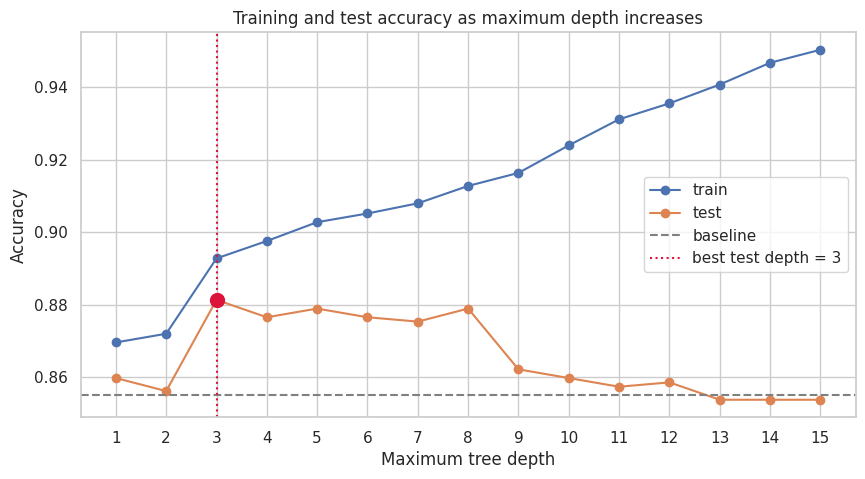

In [92]:
plt.figure(figsize=(10, 5))
plt.plot(depth_results["max_depth"], depth_results["train_accuracy"], marker="o", label="train")
plt.plot(depth_results["max_depth"], depth_results["test_accuracy"], marker="o", label="test")
plt.axhline(y_test.value_counts(normalize=True).max(), color="gray", linestyle="--", label="baseline")

best_depth_row = depth_results.loc[depth_results["test_accuracy"].idxmax()]
plt.axvline(
    best_depth_row["max_depth"],
    color="crimson",
    linestyle=":",
    label=f"best test depth = {int(best_depth_row['max_depth'])}",
)
plt.scatter(
    best_depth_row["max_depth"],
    best_depth_row["test_accuracy"],
    color="crimson",
    s=100,
    zorder=5,
)
plt.xlabel("Maximum tree depth")
plt.ylabel("Accuracy")
plt.xticks(depth_results["max_depth"])
plt.title("Training and test accuracy as maximum depth increases")
plt.legend();

### Depth decision

Choose a depth for the final comparison. Do not automatically choose the deepest tree.

> **Chosen depth:**  
> **Evidence from train/test performance:**  
> **Evidence from interpretability or number of leaves:**

In [93]:
# Replace this value with your group's choice.
chosen_depth = 3

final_tree = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=chosen_depth,
    random_state=42,
)
final_tree.fit(X_train, y_train)

DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=42)

## 7. Comparison model: logistic regression

Fit logistic regression to the **same training rows and same two features**. Keeping the data fixed makes the model comparison fair.

Because logistic regression is sensitive to feature scale, place `StandardScaler` and `LogisticRegression` in a pipeline.

In [96]:
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42),
)

logistic_model.fit(X, y)

print("Logistic test accuracy:", ...)
print("Tree test accuracy:", ...)

Logistic test accuracy: Ellipsis
Tree test accuracy: Ellipsis


### Accuracy is not the whole business question

Suppose the company can contact only 20% of its customers with a retention offer. It does not need only a final zero/one prediction—it needs a useful **ranking** of customers from most to least likely to churn.

That is where cumulative gain and lift become useful.

## 8. Cumulative gain and lift

### Cumulative gain

Sort customers from highest to lowest predicted probability. At a population fraction $q$:

$$
\text{Gain}(q)=\frac{\text{churners found in the top }q}{\text{all churners}}
$$

If the top 20% of ranked customers contains 50% of all churners, the gain at 20% is 0.50.

### Lift

Lift compares the model with random selection:

$$
\text{Lift}(q)=\frac{\text{Gain}(q)}{q}
$$

In the example above, lift at 20% is $0.50/0.20=2.5$. The model finds churners at 2.5 times the random-selection rate.

- A lift of **1** means no improvement over random targeting.
- A larger lift is better at the selected targeting fraction.
- Lift is always tied to a fraction such as the top 10%, 20%, or 30%.

### Quick calculation

A campaign can contact 10% of 2,000 customers. There are 160 churners in the full population, and 48 of them appear in the model's top 10%.

1. How many customers can the campaign contact?
2. What is the cumulative gain at 10%?
3. What is the lift at 10%?
4. Interpret the lift in one sentence.

In [99]:
# Check your arithmetic here.
gain_at_10 = 48/160
lift_at_10 = gain_at_10/160
print(gain_at_10)
print(lift_at_10)

0.3
0.001875


### Plot gain and lift with `scikitplot`

`scikitplot` builds the cumulative-gain and lift curves from the true test outcomes and the two-column probability output produced by `predict_proba()`.

The first run may install `scikit-plot` in your notebook environment.

In [103]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("scikitplot") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "scikit-plot"])

# Compatibility for older scikit-plot releases used with newer SciPy versions.
import scipy
if not hasattr(scipy, "interp"):
    scipy.interp = np.interp

import scikitplot as skplt

### Compare the two models

1. Generate the full two-column test probabilities for `final_tree` and `logistic_model`.
2. Plot a cumulative-gain curve for each model.
3. Plot a lift curve for each model.
4. Compare the positive-class curves at the top 10%, 20%, and 30% of customers.

In [108]:
tree_probabilities = final_tree.predict_proba(X_test)

# Complete after fitting logistic_model.
logistic_probabilities = logistic_model.predict_proba(X_test)

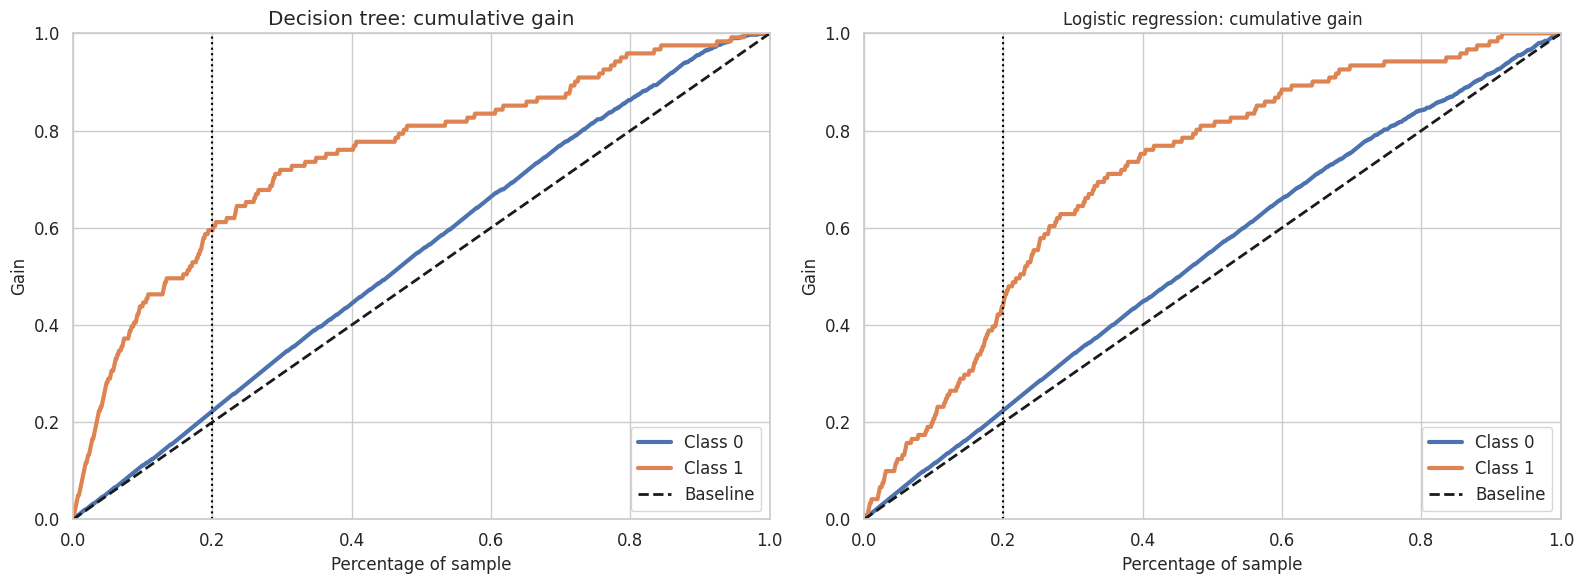

In [110]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

skplt.metrics.plot_cumulative_gain(
    y_test,
    tree_probabilities,
    ax=axes[0],
    title="Decision tree: cumulative gain",
)

# Uncomment after creating logistic_probabilities.
skplt.metrics.plot_cumulative_gain(
    y_test,
    logistic_probabilities,
    ax=axes[1],
    title="Logistic regression: cumulative gain",
)

axes[0].axvline(0.20, color="black", linestyle=":", label="contact 20%")
axes[1].axvline(0.20, color="black", linestyle=":", label="contact 20%")
axes[1].set_title("Logistic regression: cumulative gain")
plt.tight_layout();

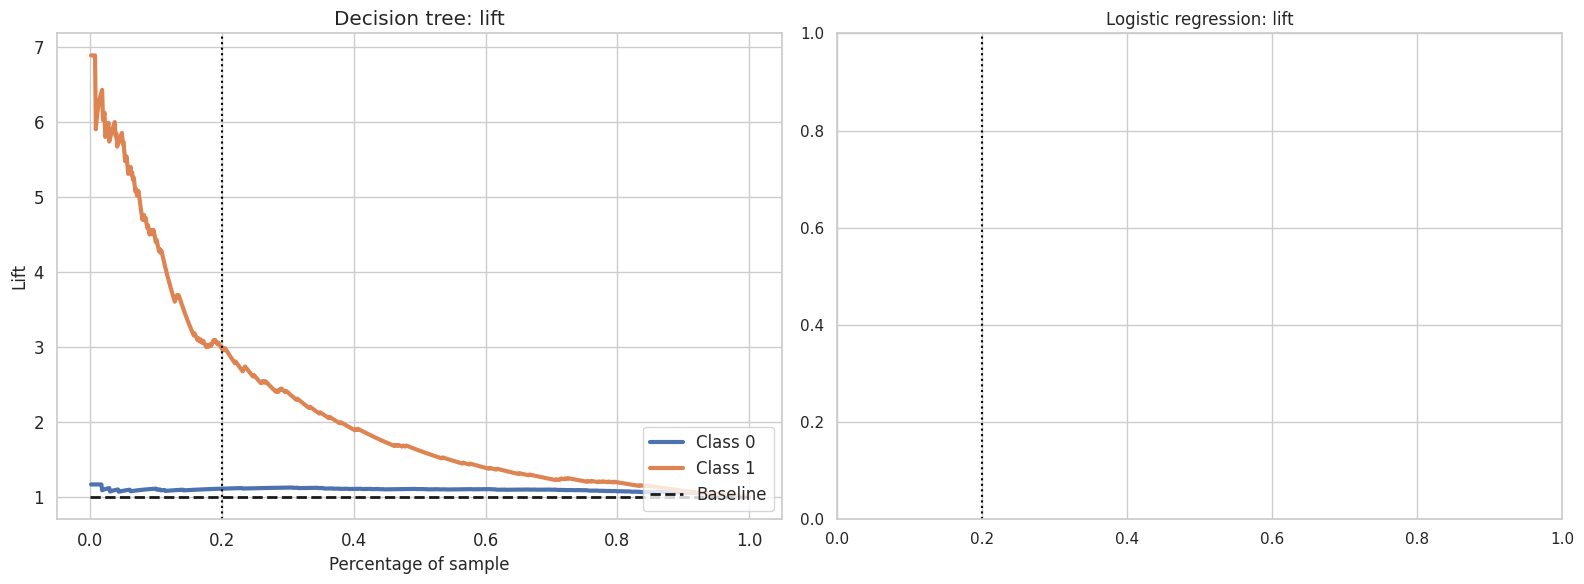

In [111]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

skplt.metrics.plot_lift_curve(
    y_test,
    tree_probabilities,
    ax=axes[0],
    title="Decision tree: lift",
)

# Uncomment after creating logistic_probabilities.
# skplt.metrics.plot_lift_curve(
#     y_test,
#     logistic_probabilities,
#     ax=axes[1],
#     title="Logistic regression: lift",
# )

axes[0].axvline(0.20, color="black", linestyle=":", label="contact 20%")
axes[1].axvline(0.20, color="black", linestyle=":", label="contact 20%")
axes[1].set_title("Logistic regression: lift")
plt.tight_layout();

## 9. Model recommendation

Your group has five minutes to prepare a brief recommendation.

Assume the company can contact only the top 20% of customers.

Report:

1. the test accuracy of each model;
2. the approximate gain at 20% for each model, read from the curves;
3. the approximate lift at 20% for each model, read from the curves;
4. which model you recommend;
5. one reason the company should be cautious about acting on the model.

> **Recommendation:**  
> **Evidence:**  
> **Caution:**

## Exit reflection

Answer in one or two sentences each.

1. What does entropy measure in a decision-tree node?
2. Why might a deeper tree have higher training accuracy but lower test accuracy?
3. If a model has lift of 2.0 at 20%, what does that mean?
4. Did accuracy and lift lead your group to the same model choice? Explain.
5. What is one question you still have about decision trees?

## Optional extensions

- Add more churn features and compare the new lift at 20%.
- Compare `criterion="entropy"` with `criterion="gini"`.
- Explore `min_samples_leaf` as another way to control tree complexity.
- Compare feature importance with logistic-regression coefficients, noting that these quantities have different meanings.